In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("credit_risk_dataset.csv")

In [3]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [4]:
# EDA

In [5]:
df.shape

(32581, 12)

In [6]:
df.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [8]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [9]:
df.head()
df['loan_status'].unique()

array([1, 0])

In [10]:
# Checking class imbalance
df['loan_status'].value_counts()

loan_status
0    25473
1     7108
Name: count, dtype: int64

<Axes: xlabel='loan_status', ylabel='count'>

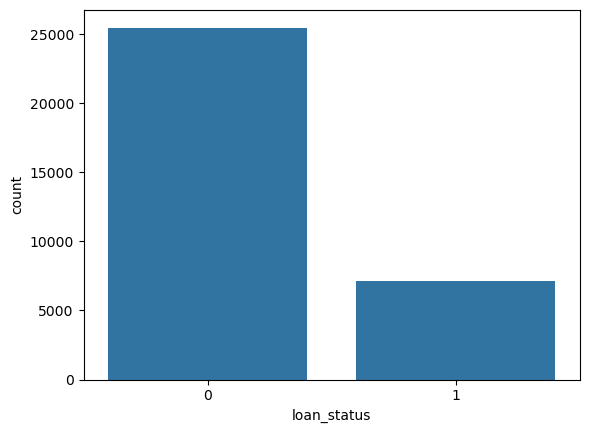

In [11]:
sns.countplot(x="loan_status", data=df)

In [12]:
#Outlier check

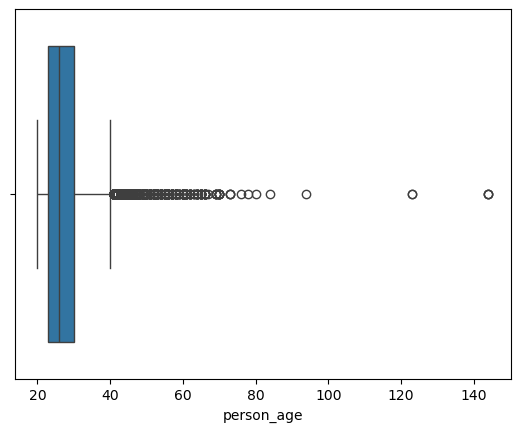

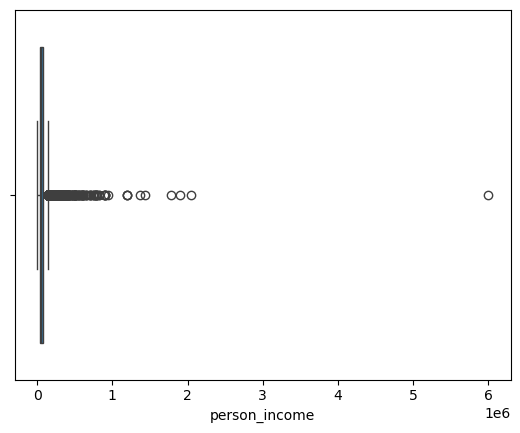

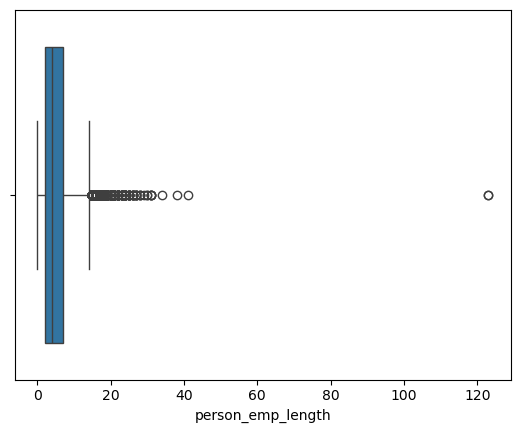

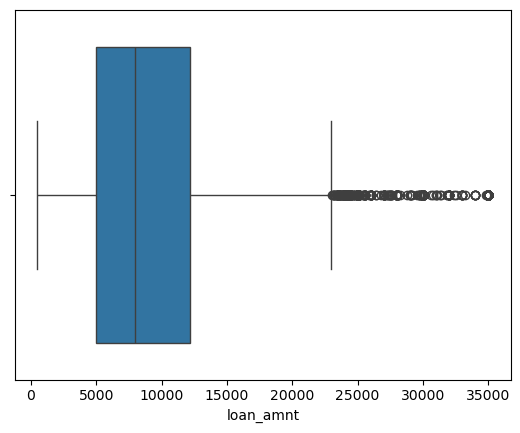

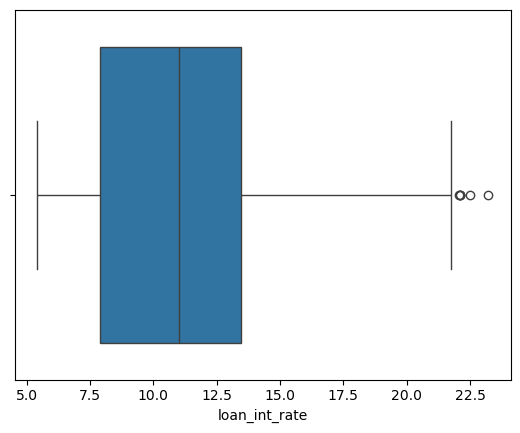

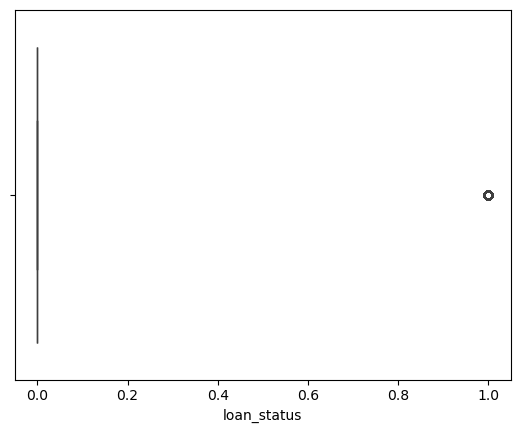

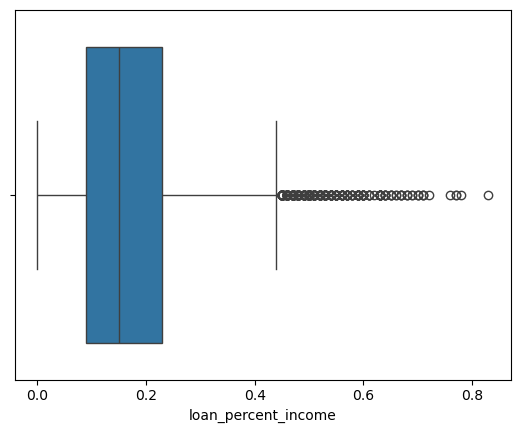

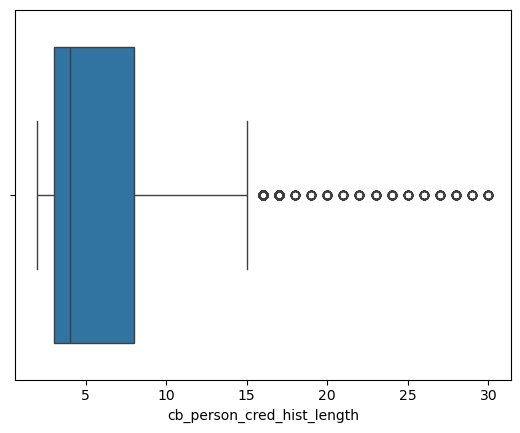

In [13]:
numerical_cols = df.select_dtypes(include=np.number)
numerical_cols.columns

for i in numerical_cols:
    sns.boxplot(x=df[i])
    plt.show()



In [14]:
age = df['person_age'] > 100
age.sum()

np.int64(5)

<Axes: >

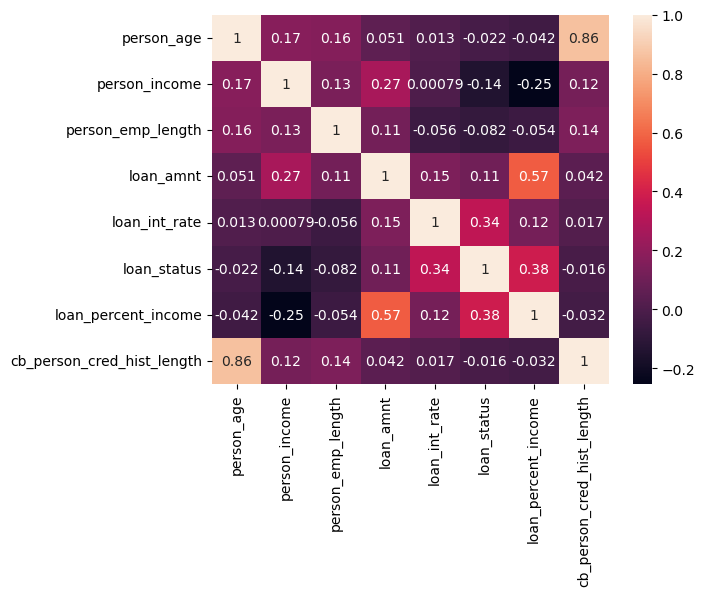

In [15]:
# Correlation check
sns.heatmap(df.corr(numeric_only=True), annot=True)

In [16]:
#clean data

In [17]:
df_copy = df.copy()

In [18]:
#Remove duplicate rows
print(f"Orginal rows: {df_copy.shape[0]}")

df_copy.drop_duplicates(inplace=True)
print(f"rows after removing duplicates : {df_copy.shape[0]}")

# Remove impossible age and extra work experience
#here remove ages below 18 or above 100
df_clean = df_copy[df_copy['person_age'] >=18]
df_clean = df_copy[df_copy['person_age'] <=100]


# Remove employment length greater than age or extreme outliers (>60)
df_clean = df_clean[df_clean['person_emp_length'] <= df_clean['person_age']]
df_clean = df_clean[df_clean['person_emp_length'] <= 60]

#remove the rows with zero or negative income and loan amount.
df_clean = df_clean[df_clean['loan_amnt'] > 0]

Orginal rows: 32581
rows after removing duplicates : 32416


In [19]:
df_clean.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,31522.000000,3.152200e+04,31522.000000,31522.000000,28495.000000,31522.000000,31522.000000,31522.000000
mean,27.742529,6.650168e+04,4.782850,9663.771334,11.045220,0.215944,0.169658,5.816097
std,6.218713,5.275216e+04,4.037343,6334.787700,3.230786,0.411482,0.106296,4.063622
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.943800e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.600000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,8.000000e+04,7.000000,12500.000000,13.480000,0.000000,0.230000,8.000000
max,94.000000,2.039784e+06,41.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [20]:
# Train test split
x = df_clean.drop('loan_status', axis=1)
y = df_clean['loan_status']

In [21]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [22]:
numeric_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
                   'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']     #standard scaler

categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']    #onehot encoding

In [23]:
# To handle class imbalance we use smote and class weight so class weight take dhyan more on 
# low class (minority class)
#0 -> no loan (most)
#1 -> yes loan
y_train.value_counts()

loan_status
0    19772
1     5445
Name: count, dtype: int64

In [24]:
neg,pos = np.bincount(y_train)
scale_weights = neg/pos

In [25]:
#Pipeline and columntransformer
#Logistic Regression : Impute + Scale Numeric, impute + one-hot encoding

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder

preprocessor_lr = ColumnTransformer(    #Columntransformer is the thing which devides(transfer) columns in their respective pipeline
    transformers=[
        #this is numerical columns pipeline
        ('num', Pipeline([    
            ('imputer', SimpleImputer(strategy='median')),  #It handles null values using median
            ('scaler', StandardScaler())   #then we apply standard scaler scale value bet 0 and 1
        ]), numeric_cols),

        # Pipeline for categorical columns
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy="constant", fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ]
)

In [26]:
# Pipeline for Xgboost : impute numeric only(No scaling), impute + one hot encoding
#bcz xgboost do scaling on their own
preprocessor_xg = ColumnTransformer(    #Columntransformer is the thing which devides(transfer) columns in their respective pipeline
    transformers=[
        
        #this is numerical columns pipeline
        ('num', Pipeline([    
            ('imputer', SimpleImputer(strategy='median')),  #It handles null values using median
        ]), numeric_cols),

        
        # Pipeline for categorical columns
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy="constant", fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ]
)

In [27]:
# Cross Validation 
#One single train-test split may not be reliable.
#We split the training data into five folds instead.
#Each fold keeps the same default vs repaid ratio.
#We check the model's score across all folds.

In [28]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'roc_auc' : 'roc_auc',
    'accuracy': 'accuracy',
    'recall' : 'recall',
    'f1' : 'f1'
}

In [29]:
#Logistic Regression model
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'))
])
lr_cv_pipeline

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [30]:
# Xg Boost moddel
from xgboost import XGBClassifier
xgb_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.1,
        scale_pos_weight= scale_weights, random_state=42
    ))
])
xgb_cv_pipeline

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [31]:

for cv_name, pipe in [("Logistic Regression", lr_cv_pipeline),
                      ("XGBoost", xgb_cv_pipeline)]:

                      cv_results = cross_validate(pipe, x_train , y_train, cv=cv, scoring=scoring, n_jobs=-1)

                      print(cv_name)
                      print(f"ROC-AUC : {cv_results['test_roc_auc'].mean()}")
                      print(f"Accuracy : {cv_results['test_accuracy'].mean()}")
                      
                      print(f"Recall : {cv_results['test_recall'].mean()}")
                      print(f"F1 : {cv_results['test_f1'].mean()}")
                      print()

Logistic Regression
ROC-AUC : 0.8705112830525306
Accuracy : 0.8115949542892269
Recall : 0.7781450872359963
F1 : 0.6408013995933108

XGBoost
ROC-AUC : 0.9470945968526715
Accuracy : 0.917952083139717
Recall : 0.7963269054178144
F1 : 0.8073360762846882



In [32]:
cv_results

{'fit_time': array([2.82625461, 2.8100636 , 2.97448468, 2.97198987, 2.80325007]),
 'score_time': array([0.31317115, 0.28062749, 0.29069972, 0.33275771, 0.28694177]),
 'test_roc_auc': array([0.95037143, 0.93802547, 0.94787183, 0.94916053, 0.95004373]),
 'test_accuracy': array([0.92089611, 0.91732752, 0.91631965, 0.91929407, 0.91592306]),
 'test_recall': array([0.80440771, 0.76767677, 0.79522498, 0.80165289, 0.81267218]),
 'test_f1': array([0.81450488, 0.80038296, 0.80408542, 0.81096145, 0.80674567])}

In [33]:
# Base line model for Logistic regression
from sklearn.pipeline import Pipeline
baseline_model = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(class_weight="balanced"))
])
baseline_model.fit(x_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [34]:
#Xg_boost hyperperametr tuning
xg_model =  Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier( learning_rate=0.1,
        scale_pos_weight= scale_weights, random_state=42
    ))
])
xg_model.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [35]:
# Evaluation Helper Function

#We have to evaluate Logistic Model and XGBoost model on the basis of their metrics

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, precision_recall_curve
def evaluate_model(model_name, model, X_test, y_test, threshold=None):
  y_pred_prob = model.predict_proba(X_test)[:,1]

  if threshold:
    y_pred = (y_pred_prob > threshold).astype(int)
  else:
    y_pred = model.predict(x_test)

  #Metrics
  accuracy     = accuracy_score(y_test, y_pred)    #Overall model's preformance
  precision    = precision_score(y_test, y_pred)   #When the model says 1, how oftenly is it actually 1.
  recall       = recall_score(y_test, y_pred)      #of the actual 1 how many did the model catches
  f1           = f1_score(y_test, y_pred)          #Harmonic mean of precision and recall

  conf_matrix   = confusion_matrix(y_test, y_pred)
  class_report  = classification_report(y_test, y_pred)


  print(f"{model_name} Metrics:")
  if threshold is not None: # Only print threshold if provided
    print(f"Used Threshold : {threshold:.2f}")
  print(f"Accuracy : {accuracy:.2f}")
  print(f"Precision : {precision:.2f}")
  print(f"Recall : {recall:.2f}")
  print(f"F1 : {f1:.2f}")
  print()
  print(f"{model_name} Classification Report:")
  print(class_report)


  #Plotting confusion matrix
  sns.heatmap(conf_matrix, annot=True, fmt="d")
  plt.title(f"{model_name} Confusion Matrix")
  plt.ylabel("Actual Values")
  plt.xlabel("Predicted Values")
  plt.show()


  #Plotting ROC-AUC curve
  precisions, recalls, threshold = precision_recall_curve(y_test, y_pred_prob)
  plt.plot(recalls, precisions)
  plt.xlabel("Recall")
  plt.ylabel("Precision")
  plt.title(f"{model_name} Precision-Recall Curve")
  plt.show()
     

Baseline Logistic Model Metrics:
Accuracy : 0.82
Precision : 0.56
Recall : 0.79
F1 : 0.65

Baseline Logistic Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



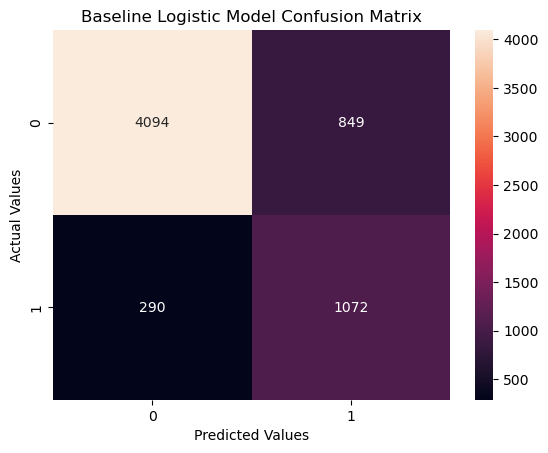

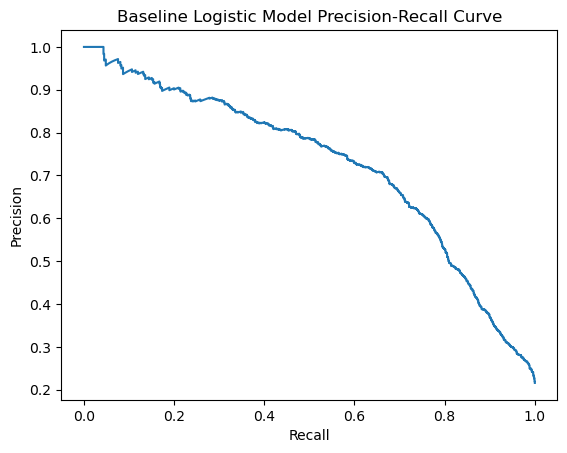

In [36]:

evaluate_model("Baseline Logistic Model", baseline_model ,x_test, y_test)

XGBoost Metrics:
Accuracy : 0.92
Precision : 0.82
Recall : 0.79
F1 : 0.81

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      4943
           1       0.82      0.79      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.87      0.88      6305
weighted avg       0.92      0.92      0.92      6305



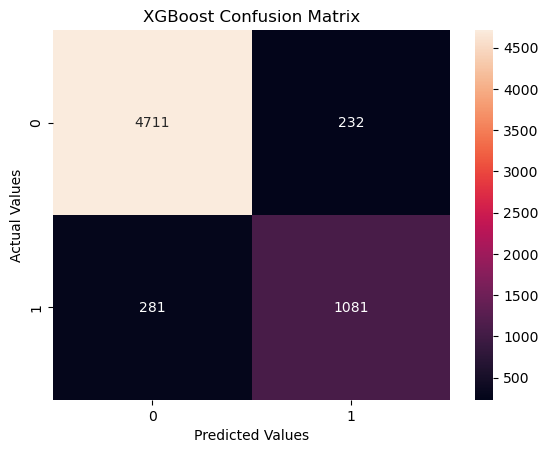

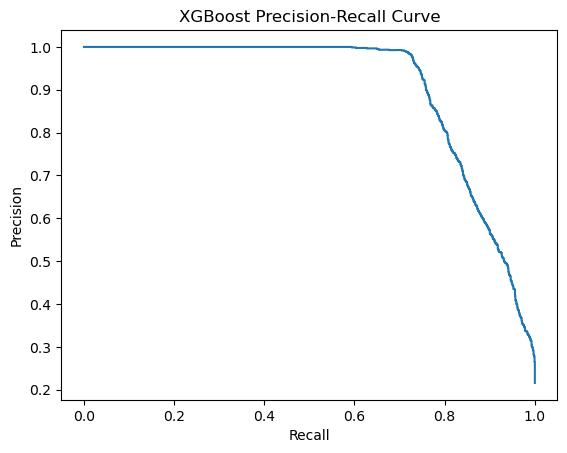

In [37]:
# Evalution of xgboost model
evaluate_model("XGBoost", xg_model, x_test, y_test)

In [38]:
# Hyperperametr Tuning
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

param_grid = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth" : randint(3,9),
    "classifier__learning_rate" : uniform(0.01, 0.5),
    "classifier__subsample": uniform(0.6,0.4), #Rows sampling
    "classifier__colsample_bytree" :uniform(0.6,0.4), #column sampling
    "classifier__min_child_weight": randint(1, 10),
    "classifier__gamma": uniform(0 , 5)
}
# lower gamma -> more splits -> complex tree -> higher overfitting risk
# higher gamma -> less splits ->  simpler tree -> low overfitting
     

random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1
)

random_search.fit(x_train, y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


,estimator,"Pipeline(step...=None, ...))])"
,param_distributions,"{'classifier__colsample_bytree': <scipy.stats....001E31DC4F9D0>, 'classifier__gamma': <scipy.stats....001E31DBD8510>, 'classifier__learning_rate': <scipy.stats....001E31DAEFE00>, 'classifier__max_depth': <scipy.stats....001E31DC4F390>, ...}"
,n_iter,150
,scoring,'average_precision'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [39]:
print(f"Score after performing Tunning {random_search.best_score_:.2f}")

Score after performing Tunning 0.90


In [40]:

random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.8467239430572293),
 'classifier__gamma': np.float64(1.6096192887320466),
 'classifier__learning_rate': np.float64(0.13404167983762405),
 'classifier__max_depth': 7,
 'classifier__min_child_weight': 5,
 'classifier__n_estimators': 371,
 'classifier__subsample': np.float64(0.8893358098750437)}

Logistic Regression Metrics:
Accuracy : 0.82
Precision : 0.56
Recall : 0.79
F1 : 0.65

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



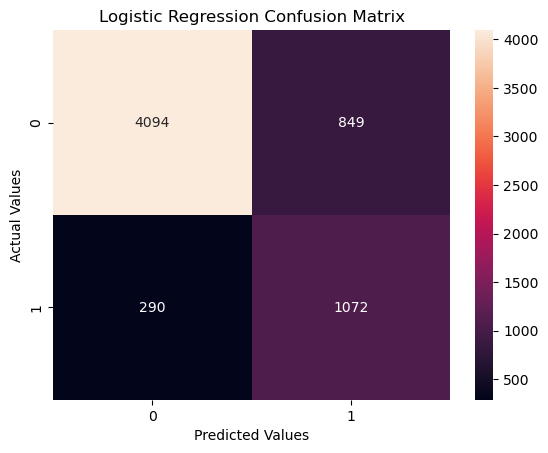

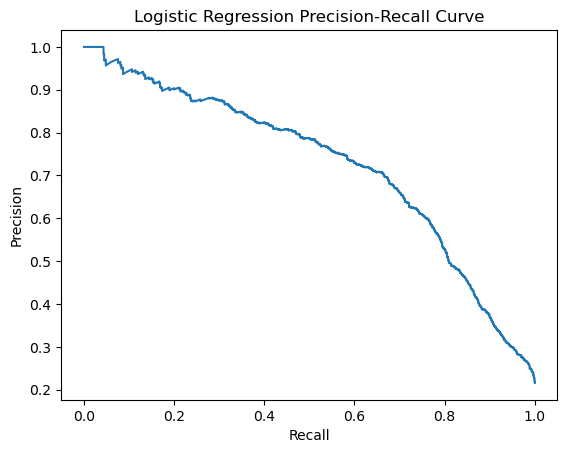

In [41]:
evaluate_model("Logistic Regression", baseline_model, x_test, y_test)

XGBoost Metrics:
Accuracy : 0.92
Precision : 0.84
Recall : 0.80
F1 : 0.82

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.96      0.95      4943
           1       0.84      0.80      0.82      1362

    accuracy                           0.92      6305
   macro avg       0.89      0.88      0.89      6305
weighted avg       0.92      0.92      0.92      6305



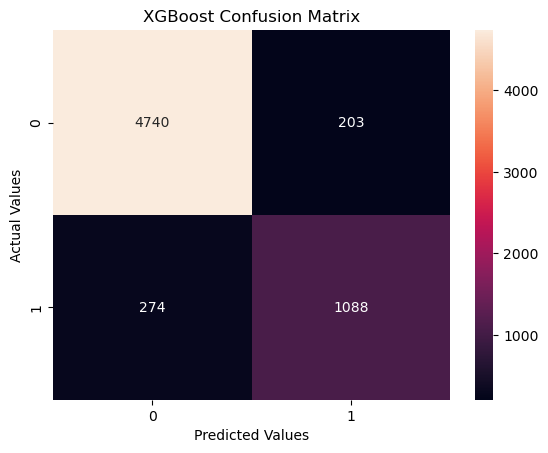

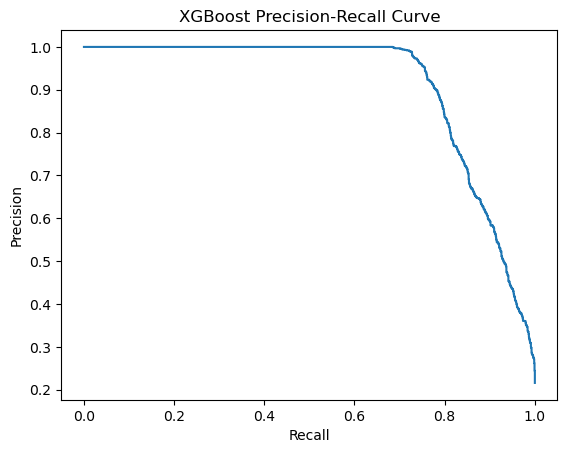

In [42]:
#Passing the XGBoost model after performing Hyperparameter Tuning
evaluate_model("XGBoost", random_search, x_test, y_test)

C:\Users\Dhruvil Kayasth\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Dhruvil Kayasth\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Dhruvil Kayasth\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Use

XGBoost Metrics:
Used Threshold : 1.00
Accuracy : 0.78
Precision : 0.00
Recall : 0.00
F1 : 0.00

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.78      1.00      0.88      4943
           1       0.00      0.00      0.00      1362

    accuracy                           0.78      6305
   macro avg       0.39      0.50      0.44      6305
weighted avg       0.61      0.78      0.69      6305



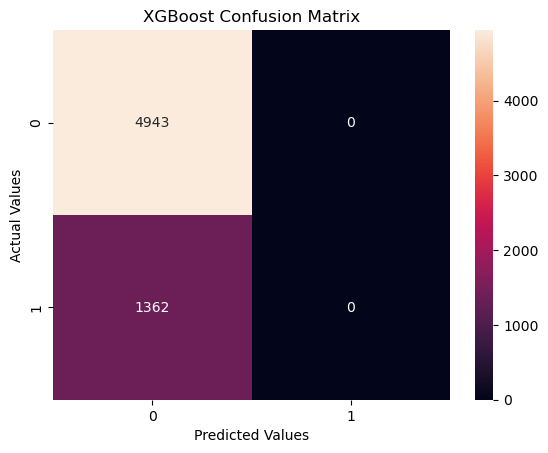

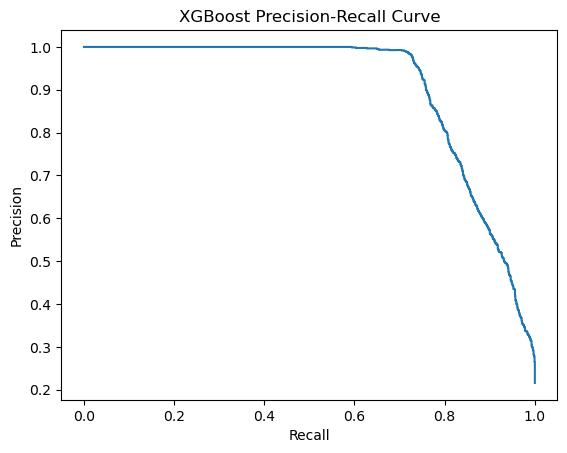

In [79]:
#Get the prob. of class 1 from XGBoost
prob = xg_model.predict_proba(x_test)[:, 1]

#For each threshold calculate Precision and Recall
precisions, recalls , thresholds = precision_recall_curve(y_test, prob)


#Calculate F1 score for each threshold
f1 = 2 * (precisions-recalls) / (precisions + recalls + 1e-9)

#Get the threshold that produces the highest f1-score
best = np.argmax(f1[:-1])
best_threshold = thresholds[best]

#Evaluate the XGBoost model using that threshold.
evaluate_model("XGBoost", xg_model, x_test, y_test, best_threshold)

In [43]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ))
])

In [44]:
rf_model.fit(x_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [45]:
y_pred = rf_model.predict(x_test)

In [46]:
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred))

Random Forest Accuracy: 0.9360824742268041


In [47]:
# Probability Calibration
"""
Methods by which we can fix the poorly calibrated model.
1. platt scaling/ sigmoid  -> Adjust the probabilites using a sigmoid curve.
2. Isotonic Regression  -> learn a flexible mapping from old prob.  -better prob.(non linear calibration)
3. Temperature Scaling  --> Adjust the confidence of neural-network predictions using one temperture.
"""

'\nMethods by which we can fix the poorly calibrated model.\n1. platt scaling/ sigmoid  -> Adjust the probabilites using a sigmoid curve.\n2. Isotonic Regression  -> learn a flexible mapping from old prob.  -better prob.(non linear calibration)\n3. Temperature Scaling  --> Adjust the confidence of neural-network predictions using one temperture.\n'

In [48]:
#1. Calibrated XGBoost model

#3. create calibration
#4. plot

In [49]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
best_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(
    best_model,
    method="sigmoid",
    cv=5
)

calibrated_model.fit(x_train, y_train)

,estimator,"Pipeline(step...=None, ...))])"
,method,'sigmoid'
,cv,5
,n_jobs,None
,ensemble,'auto'
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False


In [50]:
#2. Get Probabilites
uncalibrated = xg_model.predict_proba(x_test)[:,1]
uncalibrated


array([0.8254656 , 0.25111562, 0.9782833 , ..., 0.48520026, 0.07587515,
       0.05467961], shape=(6305,), dtype=float32)

In [51]:
calibrated = calibrated_model.predict_proba(x_test)[:,1]
calibrated

array([0.55239772, 0.02722154, 0.94822401, ..., 0.40234152, 0.0237074 ,
       0.01763107], shape=(6305,))

In [52]:
#plot
actual_uncal, predicted_uncal = calibration_curve(y_test, uncalibrated, n_bins=10)

In [53]:
actual_cal, predicted_cal = calibration_curve(y_test, calibrated, n_bins=10)

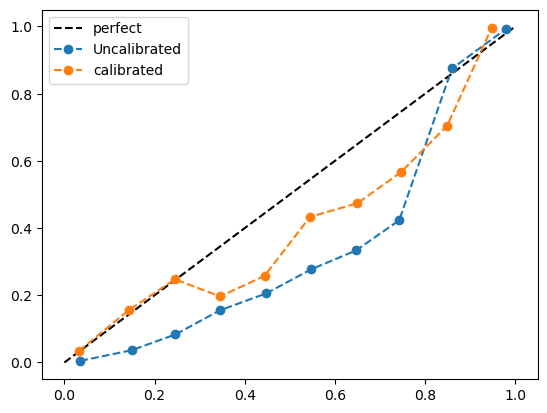

In [54]:
plt.plot([0,1], [0,1], 'k--', label='perfect')
plt.plot(
    predicted_uncal,
    actual_uncal,
    "o--",
    label="Uncalibrated"
)
plt.plot(
    predicted_cal,
    actual_cal,
    "o--",
    label="calibrated"
)
plt.legend()

In [55]:
# SHAP interpretetion
# Shap helps us understand why the modal makes a decision.
# It is a way of explanaing a "black box" model.
# Shap can tell you how each feature contributed. 

In [56]:
# SHAP tells whcih features pushed the predictions up or down and how much?

In [57]:
# 1.install shap if not exist
!pip install shap

In [58]:
import shap

In [59]:
# 2. Get the trained XGboost classifier model out of the pipeline.
#3. Transform x_test using the same preprocessing used for training.
#4. Get feature names after onehot encoding , so plota are readable

In [60]:
# 2. Get the trained XGboost classifier model out of the pipeline.
xgb_classifier = xg_model.named_steps['classifier']

In [61]:
#3. Transform x_test using the same preprocessing used for training.
x_test_transformed = xg_model.named_steps['preprocessor'].transform(x_test)

In [62]:
#4. Get feature names after onehot encoding , so plota are readable
feature_names = xg_model.named_steps['preprocessor'].get_feature_names_out()

In [63]:
#5. convert to a dataframe for cleaner SHAP plots
x_test_df = pd.DataFrame(x_test_transformed, columns=feature_names)

In [64]:
#6. create SHAP explainer built for tree-based model
explainer = shap.TreeExplainer(xgb_classifier)

In [65]:
#7. Calculate shap values for every row in the test set
shap_values = explainer.shap_values(x_test_df)
shap_values

array([[-1.7525564e-01, -1.0555401e-01,  1.2984274e-01, ...,
        -7.3516299e-03, -3.8879909e-02,  0.0000000e+00],
       [ 4.7165085e-02, -8.7262326e-01, -9.4737314e-02, ...,
        -9.2151780e-03, -7.5508673e-03,  0.0000000e+00],
       [ 7.8027323e-02,  3.5025654e+00,  1.2711690e-01, ...,
        -7.3584518e-03,  7.7456667e-04,  0.0000000e+00],
       ...,
       [-8.6244913e-03,  5.8208084e-01,  7.2391242e-02, ...,
        -9.2837382e-03, -1.1459960e-02,  0.0000000e+00],
       [ 2.0838849e-02, -1.0313793e+00,  4.3692421e-02, ...,
        -9.2305308e-03, -1.1398584e-02,  0.0000000e+00],
       [-1.3665082e-01, -5.0866711e-01,  2.6854105e-02, ...,
        -8.8342456e-03, -1.0388625e-02,  0.0000000e+00]],
      shape=(6305, 26), dtype=float32)

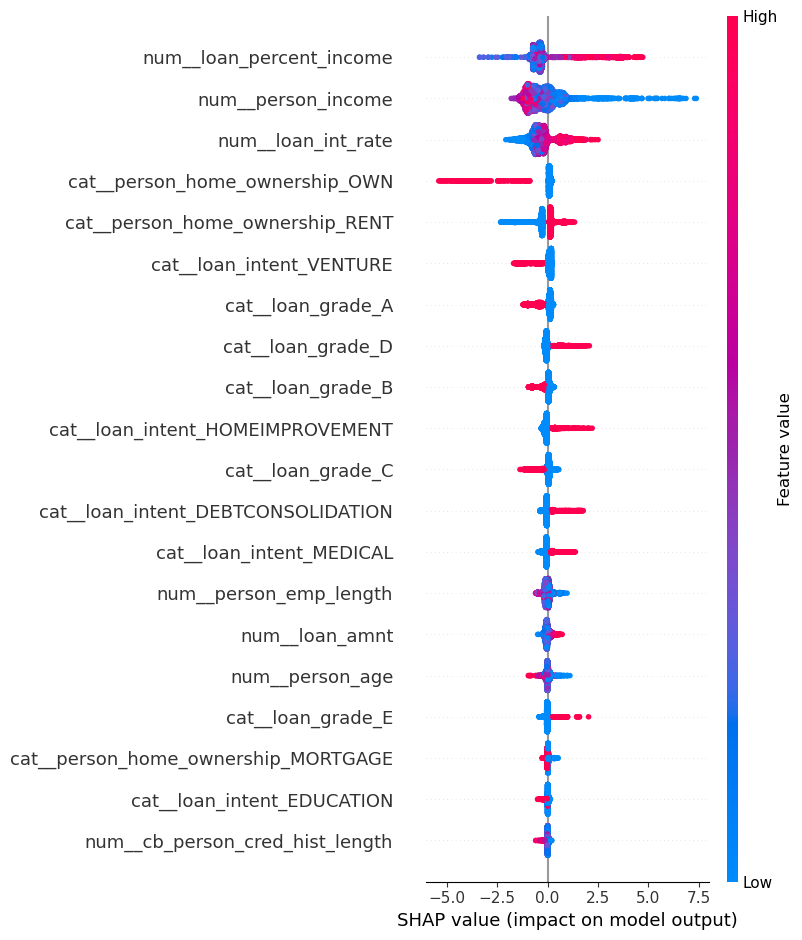

In [66]:
# Global Explanation : This shows which features matter most overall
shap.summary_plot(shap_values, x_test_df)

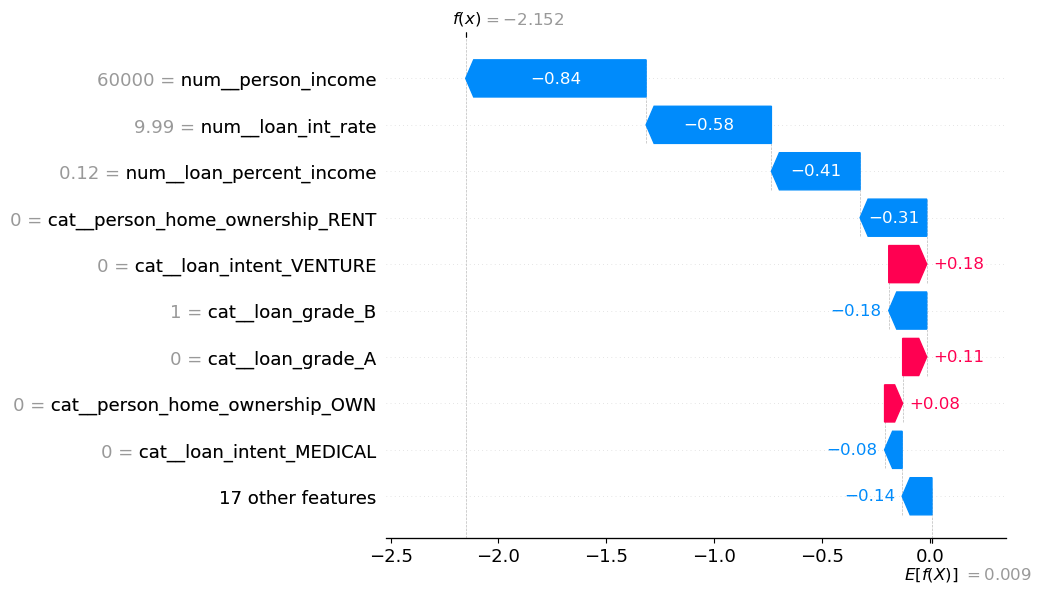

In [67]:
# Local Explanation : This shows why one specific applicant got their score.
row_index = 5
#2. draw a waterfall plot showing how each feature pushed the prediction up pr down.

shap.plots.waterfall(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,
        data = x_test_df.iloc[row_index]
    )
)

In [68]:
# Analyzing False Positives & False Negatives
# False positives are safe people but wrongly marked risky.
# False negative are risky people but wrongly marked safe.

In [69]:
# Get predictions from the best performing Xgboost model on the test set
y_pred = random_search.predict(x_test)

In [70]:
#create a dataframe to easily compare the actual and predicted values
result_df = x_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred

In [71]:
# Identify false positive : model predicted 1 , but the actual 0
false_positive = result_df[(result_df['actual'] == 0) & (result_df['predicted']==1)]

# Identify False negative : model predicted  0, but the actual 1
false_negative = result_df[(result_df['actual'] == 1) & (result_df['predicted']==0)]

In [72]:
print(f"False Positive : {len(false_positive)}")
print(f"False Negative : {len(false_negative)}")

False Positive : 203
False Negative : 274


In [73]:
# Here False Negative > False Positive 

In [75]:
import joblib

joblib.dump(calibrated_model, "credit_risk_model.pkl")

['credit_risk_model.pkl']

In [83]:
joblib.dump(best_threshold, "best_threshold.pkl")

['best_threshold.pkl']

In [82]:
from sklearn.metrics import precision_recall_curve
import numpy as np

# 1. Get probabilities from the calibrated model
calibrated_proba = calibrated_model.predict_proba(x_test)[:, 1]

# 2. Calculate precision and recall at different thresholds
precisions, recalls, thresholds = precision_recall_curve(
    y_test, calibrated_proba
)

# 3. Calculate F1 scores
f1_scores = (
    2 * (precisions * recalls) /
    (precisions + recalls + 1e-9)
)

# 4. Find the threshold that gives the highest F1 score
best_threshold = thresholds[np.argmax(f1_scores[:-1])]

print("New threshold:", best_threshold)

New threshold: 0.5240963907622158
